Номер команды - 405

Состав: Граненова Татьяна, Мироненко Мария, Рыжова Надежда, Ткач Софья

Распределение работы: 
- Граненова Татьяна - рекомендации, ревью - классификации
- Мироненко Мария - классификация, ревью - регрессия
- Рыжова Надежда - рекомендации, ревью - классификации
- Ткач Софья - регрессия, ревью - рекомендации

Три CSV файла: `variant_5_classification.csv` (Кредит), `variant_7_regression.csv` (Выручка), `variant_9_recsys.csv` (Товары)

### Мироненко Мария - классификация

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("variant_5_classification.csv")

y_true = df["y_true"]
y_pred = df["y_pred"]
y_score = df["y_score"]

In [20]:
print("Количество строк:", len(df))
print("Столбцы:", df.columns.tolist())
print("Пропущенные значения:")
print(df.isnull().sum())

print("\nРаспределение классов:")
print(df["y_true"].value_counts())

print("\nДоля класса 1:")
print(df["y_true"].mean() * 100, "%")

print("\nСовпадение с порогом 0.5:")
print(((df["y_score"] >= 0.5).astype(int) == df["y_pred"]).mean() * 100, "%")

Количество строк: 450
Столбцы: ['y_true', 'y_pred', 'y_score']
Пропущенные значения:
y_true     0
y_pred     0
y_score    0
dtype: int64

Распределение классов:
y_true
0    281
1    169
Name: count, dtype: int64

Доля класса 1:
37.55555555555555 %

Совпадение с порогом 0.5:
100.0 %


In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = df["y_true"]
y_pred = df["y_pred"]

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")

Accuracy: 0.8200
Precision: 0.7391
Recall: 0.8047
F1: 0.7705


Матрица ошибок:
[[233  48]
 [ 33 136]]


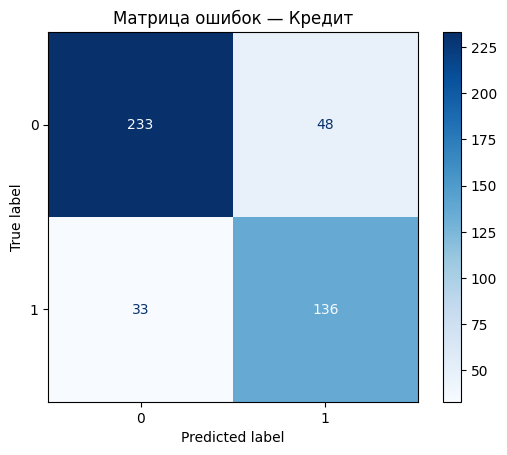

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

print("Матрица ошибок:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(cmap="Blues")
plt.title("Матрица ошибок — Кредит")
plt.show()

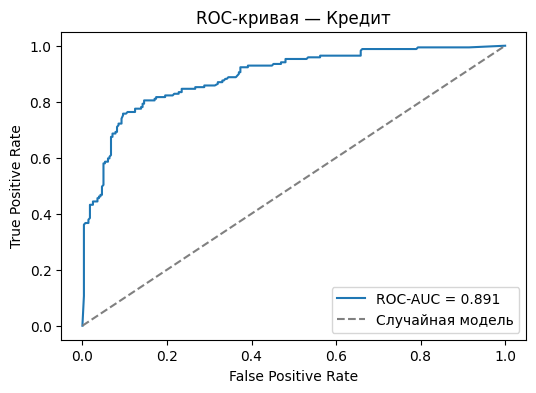

ROC-AUC: 0.891


In [23]:
from sklearn.metrics import roc_curve, roc_auc_score

y_score = df["y_score"]

roc_auc = roc_auc_score(y_true, y_score)
fpr, tpr, _ = roc_curve(y_true, y_score)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="grey",
         label="Случайная модель")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая — Кредит")
plt.legend()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")

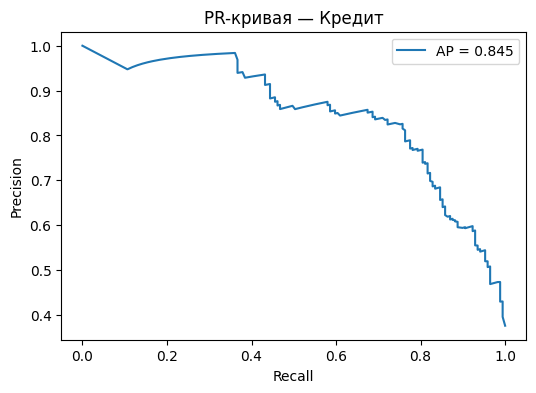

AP: 0.845


In [24]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_values, recall_values, _ = precision_recall_curve(y_true, y_score)
ap = average_precision_score(y_true, y_score)

plt.figure(figsize=(6, 4))
plt.plot(recall_values, precision_values, label=f"AP = {ap:.3f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR-кривая — Кредит")
plt.legend()
plt.show()

print(f"AP: {ap:.3f}")

In [25]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

for t in [0.3, 0.5, 0.8]:
    y_pred_t = (y_score >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred_t).ravel()

    precision = precision_score(y_true, y_pred_t)
    recall = recall_score(y_true, y_pred_t)

    print(f"\nПорог: {t}")
    print(f"Сигналов: {y_pred_t.sum()}")
    print(f"FP: {fp}, FN: {fn}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")


Порог: 0.3
Сигналов: 320
FP: 158, FN: 7
Precision: 50.62%
Recall: 95.86%

Порог: 0.5
Сигналов: 184
FP: 48, FN: 33
Precision: 73.91%
Recall: 80.47%

Порог: 0.8
Сигналов: 56
FP: 1, FN: 114
Precision: 98.21%
Recall: 32.54%


In [26]:
from sklearn.metrics import log_loss

ll = log_loss(y_true, y_score)

print(f"LogLoss: {ll:.3f}")

LogLoss: 0.586


### Вывод по классификации — вариант 5 «Кредит»

Модель правильно классифицирует 82% кредитных заявок (Accuracy = 0,82).

- Precision = 73,91% — среди одобренных моделью заявок 73,91% соответствуют классу 1.
- Recall = 80,47% — модель обнаруживает 80,47% заявок класса 1.
- ROC-AUC = 0,891, AP = 0,845 — модель достаточно хорошо различает классы.
- LogLoss = 0,586 — оценка качества вероятностных прогнозов при условии, что `y_score` является вероятностью.

Сравнение порогов:

- 0,3 — больше одобрений, но 158 ошибочных решений FP.
- 0,5 — 48 ошибочных одобрений и 33 ошибочных отказа.
- 0,8 — минимальное число ошибочных одобрений (1), но 114 ошибочных отказов.

Основная метрика — Precision, поскольку ошибочное одобрение кредита может привести к финансовым потерям банка.

Дополнительное ограничение — Recall, чтобы не отказывать слишком большому числу подходящих клиентов.

Итог: модель показывает хорошие результаты, но для запуска необходимо определить допустимое количество ошибок и проверить качество на новых данных. Пока данных для решения о запуске недостаточно.

#### Ревью (Татьяна Гранёнова)

1. Проверка знаменателей, положительного класса, единиц и значения k

Всё выбрано верно

2. Сопоставление чисел с исходными строками или матрицей ошибок
Если посчитать вручную метрики для произвольных значений, то
- Accuracy примерно равно 0.82.
- Precision примерно равно 0.739.
- Recall примерно равно 0.805.
При сверке с графиками значения сходятся и на PR, и на ROC кривой

ROC-AUC = 0.891, AP = 0.845 эти значения выглядят правдоподобно.

3. Проверка подписей графиков и соответствие выводов
Подписи графиков верны, выводов соответствуют действительности

4. Перезапуск ноутбука в чистом состоянии
После перезапуска всё работает.


### Ткач Софья - регрессия

In [27]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error, mean_absolute_percentage_error

In [28]:
data = pd.read_csv('variant_7_regression.csv', sep = ",")
data

,y_true,y_pred
0,1377.14,1393.29
1,113.71,70.61
2,151.37,21.33
3,1249.92,1196.87
4,137.10,166.45
...,...,...
295,403.82,522.06
296,274.74,83.24
297,294.64,283.05
298,844.16,717.24


In [29]:
print(f"Размер: {data.shape}")
print(f"Количестов пустых: \n{data.isna().sum()}")
print(f"Анализ y_true: \n{data["y_true"].describe()}")

Размер: (300, 2)
Количестов пустых: 
y_true    0
y_pred    0
dtype: int64
Анализ y_true: 
count     300.000000
mean      503.736067
std       330.928740
min        20.310000
25%       255.165000
50%       424.615000
75%       674.052500
max      1920.740000
Name: y_true, dtype: float64


In [30]:
y_true = data["y_true"]
y_pred = data["y_pred"]

In [31]:
print(f"MAE = {mean_absolute_error(y_true, y_pred):.4f}")
print(f"MSE = {mean_squared_error(y_true, y_pred):.4f}")
print(f"RMSE = {root_mean_squared_error(y_true, y_pred):.4f}")
print(f"R2 = {r2_score(y_true, y_pred):.4f}")
print(f"MAPE = {mean_absolute_percentage_error(y_true, y_pred):.4f}")

MAE = 71.2359
MSE = 7887.7384
RMSE = 88.8129
R2 = 0.9277
MAPE = 0.2647


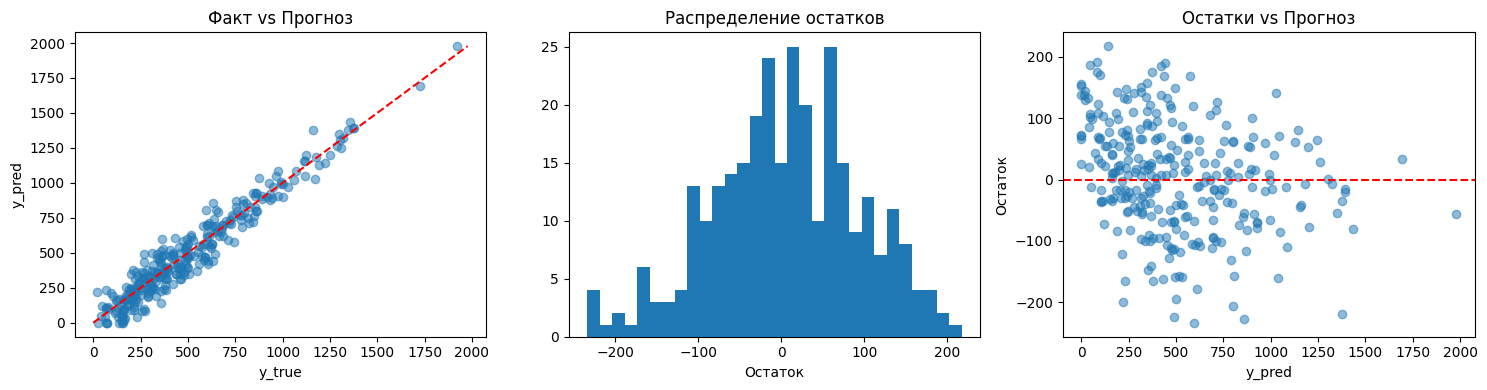

In [32]:
residuals = y_true - y_pred

fig, ax = plt.subplots(1,3, figsize=(15,4))
ax[0].scatter(y_true, y_pred, alpha=0.5)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
ax[0].plot(lims, lims, '--', color='red')
ax[0].set_xlabel('y_true'); ax[0].set_ylabel('y_pred'); ax[0].set_title('Факт vs Прогноз')

ax[1].hist(residuals, bins=30)
ax[1].set_title('Распределение остатков'); ax[1].set_xlabel('Остаток')

ax[2].scatter(y_pred, residuals, alpha=0.5)
ax[2].axhline(0, color='red', linestyle='--')
ax[2].set_xlabel('y_pred'); ax[2].set_ylabel('Остаток'); ax[2].set_title('Остатки vs Прогноз')
plt.tight_layout(); plt.show()

#### Выводы

- R2 = 0.9277 и MAPE = 0.2647 означает, что модель объясняет 92,8% дисперсии фактической выручки и средняя относительная ошибка составляет около 26,5%. Модель в целом хорошо улавливает тренды, но в среднем может ошибаться на четверть от фактической суммы. 

- MAE = 71.24 и RMSE = 88.81
RMSE выше MAE, что указывает на наличие крупных выбросов, что подтверждается графиком остатков, где есть точки с ошибкой более 200 по модулю, получается иногда модель может существенно недооценить или переоценить выручку.

- Основной метрикой я бы выбрала MAPE, потому что она указывает ошибку, которая модель делает, и для более точных прогнозов мы должны стараться её минимизировать

- Требуется азобраться с выбросами и аномалиями и протестировать прогноз на реальных периодах, чтобы увидеть, как ошибка влияет на бизнес-решения. Сейчас запускать модель хорошо видит тренд, но может ошибиться на четверть суммы, а в отдельных случаях — и сильнее.

#### Ревью (Мироненко Мария)

1. Проверка знаменателей, целевой переменной, единиц и значения k
Всё верно

2. Сопоставление чисел с исходными данными и графиками
Связь метрик: MSE = 7887, значит RMSE = 88 - сходится.
На графике "Факт vs Прогноз" точки плотно лежат вдоль красной пунктирной линии. Разброс есть, но он визуально соответствует R2 = 0.9277 (92.7% дисперсии объяснено).
На графике «Остатки vs Прогноз» видно, что остатки распределены вокруг нуля, но есть точки, уходящие в район +-200. Это отлично подтверждает вывод про RMSE > MAE и наличие выбросов.
График «Распределение остатков» показывает колоколообразную форму, близкую к нормальной, что является хорошим знаком для линейных моделей.

3. Проверка подписей графиков и соответствие выводов
Построены верно, интерпритированы тоже

4. Перезапуск ноутбука в чистом состоянии
Всё ок

### Граненова Татьяна - рекомендации

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    log_loss, mean_absolute_error, mean_squared_error,
    r2_score, mean_absolute_percentage_error
)

In [34]:
df = pd.read_csv('variant_9_recsys.csv')
df['recommended_items'] = df['recommended_items'].apply(lambda s: [int(x) for x in s.split(';')])
df['relevant_items'] = df['relevant_items'].apply(lambda s: [int(x) for x in s.split(';')])

In [35]:
def precision_at_k(rec, rel, k):
    rec_k = rec[:k]
    return len(set(rec_k) & set(rel)) / k

def recall_at_k(rec, rel, k):
    rec_k = rec[:k]
    return len(set(rec_k) & set(rel)) / len(rel) if rel else 0

def average_precision(rec, rel, k):
    hits, score = 0, 0.0
    for i, item in enumerate(rec[:k], start=1):
        if item in rel:
            hits += 1
            score += hits / i
    return score / min(len(rel), k) if rel else 0

def reciprocal_rank(rec, rel):
    for i, item in enumerate(rec, start=1):
        if item in rel:
            return 1 / i
    return 0

def ndcg_at_k(rec, rel, k):
    dcg = sum(1/np.log2(i+1) for i, item in enumerate(rec[:k], start=1) if item in rel)
    idcg = sum(1/np.log2(i+1) for i in range(1, min(len(rel), k)+1))
    return dcg / idcg if idcg > 0 else 0

In [36]:
K = 10
df['precision_k'] = df.apply(lambda r: precision_at_k(r['recommended_items'], r['relevant_items'], K), axis=1)
df['recall_k'] = df.apply(lambda r: recall_at_k(r['recommended_items'], r['relevant_items'], K), axis=1)
df['ap'] = df.apply(lambda r: average_precision(r['recommended_items'], r['relevant_items'], K), axis=1)
df['rr'] = df.apply(lambda r: reciprocal_rank(r['recommended_items'], r['relevant_items']), axis=1)
df['ndcg'] = df.apply(lambda r: ndcg_at_k(r['recommended_items'], r['relevant_items'], K), axis=1)

MAP = df['ap'].mean()
MRR = df['rr'].mean()
mean_ndcg = df['ndcg'].mean()
print(f"Precision@{K}={df['precision_k'].mean():.3f}, Recall@{K}={df['recall_k'].mean():.3f}")
print(f"MAP={MAP:.3f}, MRR={MRR:.3f}, NDCG@{K}={mean_ndcg:.3f}")

Precision@10=0.015, Recall@10=0.078
MAP=0.021, MRR=0.042, NDCG@10=0.041


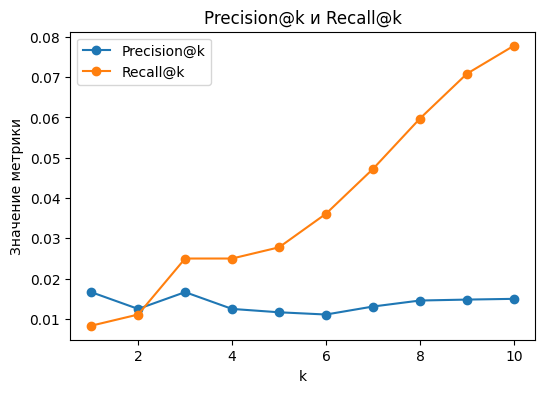

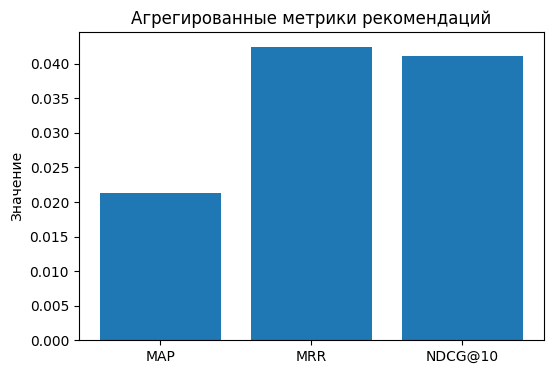

In [37]:
ks = range(1, K+1)
prec_by_k = [df.apply(lambda r: precision_at_k(r['recommended_items'], r['relevant_items'], k), axis=1).mean() for k in ks]
rec_by_k = [df.apply(lambda r: recall_at_k(r['recommended_items'], r['relevant_items'], k), axis=1).mean() for k in ks]

plt.figure(figsize=(6,4))
plt.plot(ks, prec_by_k, marker='o', label='Precision@k')
plt.plot(ks, rec_by_k, marker='o', label='Recall@k')
plt.xlabel('k'); plt.ylabel('Значение метрики'); plt.title('Precision@k и Recall@k')
plt.legend(); plt.show()

plt.figure(figsize=(6,4))
plt.bar(['MAP','MRR', f'NDCG@{K}'], [MAP, MRR, mean_ndcg])
plt.title('Агрегированные метрики рекомендаций'); plt.ylabel('Значение')
plt.show()

Наша рекомендательная система работает очень плохо. Из 10 предложенных товаров пользователю в среднем интересен только 0.15 товара (метрика Precision@10 = 0.015).Это значит, что первый экран с рекомендациями почти всегда забит не тем, что нужно покупателю. Самая важная метрика здесь - точность попадания в топ-10 (Precision@10), потому что если человек не видит нужный товар сразу, он просто уходит из магазина. Другие метрики (MAP и NDCG) тоже показывают, что система плохо сортирует товары. Есть риск, что система всем подряд показывает одни и те же популярные товары, но это нужно проверить дополнительно. Нам не хватает данных о том, кликают ли люди на эти рекомендации и покупают ли что-то в итоге. Следующий шаг, переделать алгоритм и попробовать более умные модели подбора товаров. Сейчас запускать эту систему нельзя, она будет только раздражать клиентов.
Итог: модель пока не готова к работе и требует серьезных доработок.

#### Ревью (Ткач Софья)
1. Проверка знаменателей, положительного класса, единиц и значения k**
Определены верно

2. Сопоставление чисел с исходными данными и графиками
- Сверка с графиками:
На графике «Precision@k и Recall@k»: Recall начинается с ~0.01 при k=1 и плавно растет до ~0.078 при k=10. Precision при этом держится в районе 0.01–0.015 и даже падает при увеличении k. Это классическая картина: чем больше мы показываем (k растет), тем больше находим релевантных (Recall растет), но доля «мусора» в выдаче увеличивается (Precision падает или стагнирует).
На графике «Агрегированные метрики» значения MAP ≈ 0.021, MRR ≈ 0.042, NDCG@10 ≈ 0.041. Визуально столбцы соответствуют этим числам.
Сверка с текстом вывода: автор пишет, что Precision@10 = 0.015. Если посмотреть на левый график при k=10, синяя линия действительно находится в районе 0.015 — сходится.

Значение MRR (0.042) означает, что в среднем первый релевантный товар находится на позиции 1 / 0.042 ≈ 24. Значение MAP = 0.021 очень низкое, что говорит о том, что даже если попадания есть, они стоят в самом конце списка. Это подтверждает вывод о плохой сортировке.

3. Проверка подписей графиков и соответствие выводов

Подписи графиков верны, выводы соответствуют действительности.

4. Перезапуск ноутбука в чистом состоянии

Всё работает


### Рыжова Надежда - рекомендации

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

# ==========================================
# 1. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ И МЕТРИКИ
# ==========================================

def parse_items(item_str):
    """Преобразует строку '1;73;48' в список целых чисел [1, 73, 48]"""
    if pd.isna(item_str) or str(item_str).strip() == "":
        return []
    return [int(x) for x in str(item_str).split(';')]

def precision_at_k(recs, rels, k):
    top_k = recs[:k]
    hits = len(set(top_k).intersection(set(rels)))
    return hits / k

def recall_at_k(recs, rels, k):
    top_k = recs[:k]
    hits = len(set(top_k).intersection(set(rels)))
    return hits / len(rels) if len(rels) > 0 else 0

def ap_at_k(recs, rels, k):
    # AP@k = Σ[reli * P@i] / min(|Rel|, k)
    top_k = recs[:k]
    score = 0.0
    hits = 0
    for i, item in enumerate(top_k, start=1):
        if item in rels:
            hits += 1
            score += hits / i # P@i
    return score / min(len(rels), k) if min(len(rels), k) > 0 else 0

def rr(recs, rels):
    # Reciprocal Rank (считается по всему списку)
    for i, item in enumerate(recs, start=1):
        if item in rels:
            return 1.0 / i
    return 0.0

def ndcg_at_k(recs, rels, k):
    # NDCG@k = DCG@k / IDCG@k
    top_k = recs[:k]
    dcg = 0.0
    for i, item in enumerate(top_k, start=1):
        if item in rels:
            dcg += 1.0 / math.log2(i + 1)
            
    # Идеальный порядок (все релевантные наверху)
    ideal_recs = list(rels)[:k]
    idcg = 0.0
    for i in range(1, len(ideal_recs) + 1):
        idcg += 1.0 / math.log2(i + 1)
        
    return dcg / idcg if idcg > 0 else 0.0

# ==========================================
# 2. ЗАГРУЗКА И ОБРАБОТКА ДАННЫХ
# ==========================================

df = pd.read_csv('variant_9_recsys.csv')

# Парсинг строк в списки
df['recommended_list'] = df['recommended_items'].apply(parse_items)
df['relevant_list'] = df['relevant_items'].apply(parse_items)

print("--- Обзор данных ---")
print(f"Всего пользователей: {len(df)}")
print(f"Средняя длина списка рекомендаций: {df['recommended_list'].apply(len).mean():.2f}")
print(f"Максимальная длина рекомендаций: {df['recommended_list'].apply(len).max()}")
print(f"Пользователей без релевантных объектов: {df['relevant_list'].apply(len).eq(0).sum()}\n")

# ==========================================
# 3. РАСЧЕТ МЕТРИК ПРИ K = 10
# ==========================================

K = 10
df['P@10'] = df.apply(lambda row: precision_at_k(row['recommended_list'], row['relevant_list'], K), axis=1)
df['R@10'] = df.apply(lambda row: recall_at_k(row['recommended_list'], row['relevant_list'], K), axis=1)
df['AP@10'] = df.apply(lambda row: ap_at_k(row['recommended_list'], row['relevant_list'], K), axis=1)
df['RR'] = df.apply(lambda row: rr(row['recommended_list'], row['relevant_list']), axis=1)
df['NDCG@10'] = df.apply(lambda row: ndcg_at_k(row['recommended_list'], row['relevant_list'], K), axis=1)


mean_precision_10 = df['P@10'].mean()
mean_recall_10 = df['R@10'].mean()
map_10 = df['AP@10'].mean()
mrr = df['RR'].mean()
mean_ndcg_10 = df['NDCG@10'].mean()

print(f"--- Итоговые метрики (k={K}) ---")
print(f"Mean Precision@{K}: {mean_precision_10:.3f}")
print(f"Mean Recall@{K}:    {mean_recall_10:.3f}")
print(f"MAP@{K}:            {map_10:.3f}")
print(f"MRR:               {mrr:.3f}")
print(f"Mean NDCG@{K}:      {mean_ndcg_10:.3f}\n")


users_no_hits = df[df['RR'] == 0].shape[0]
print(f"Пользователей без попаданий (RR=0): {users_no_hits} из {len(df)} ({users_no_hits/len(df)*100:.1f}%)\n")

--- Обзор данных ---
Всего пользователей: 120
Средняя длина списка рекомендаций: 10.00
Максимальная длина рекомендаций: 10
Пользователей без релевантных объектов: 0

--- Итоговые метрики (k=10) ---
Mean Precision@10: 0.015
Mean Recall@10:    0.078
MAP@10:            0.021
MRR:               0.042
Mean NDCG@10:      0.041

Пользователей без попаданий (RR=0): 102 из 120 (85.0%)



--- Пример расчета для первых 3 пользователей ---
 user_id                         recommended_list relevant_list  P@10    AP@10       RR  NDCG@10
       1   [3, 36, 27, 64, 47, 43, 23, 5, 11, 31]      [85, 68]   0.0 0.000000 0.000000 0.000000
       2 [61, 93, 14, 44, 48, 25, 94, 45, 75, 68]      [72, 94]   0.1 0.071429 0.142857 0.204382
       3  [58, 10, 33, 49, 20, 92, 82, 79, 9, 72]          [46]   0.0 0.000000 0.000000 0.000000




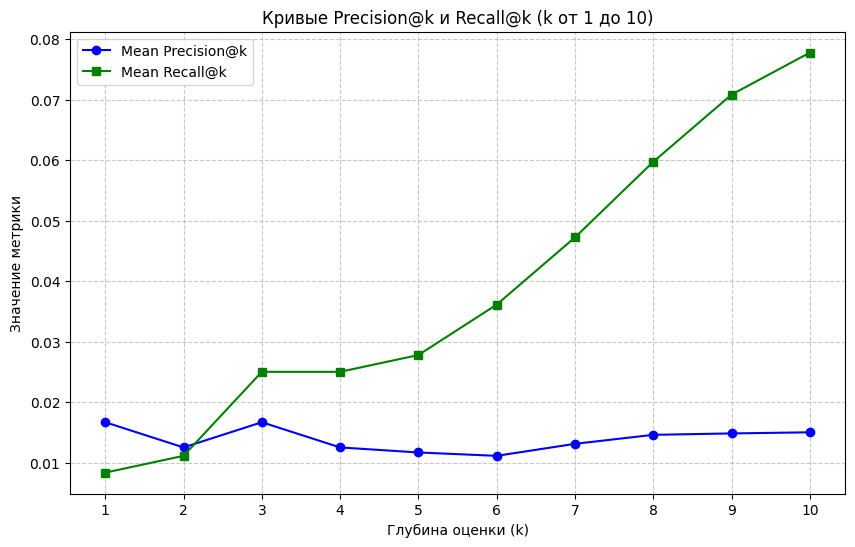

In [7]:
# Пример ручного расчета для первых 3 пользователей (слайд 15)
print("--- Пример расчета для первых 3 пользователей ---")
print(df[['user_id', 'recommended_list', 'relevant_list', 'P@10', 'AP@10', 'RR', 'NDCG@10']].head(3).to_string(index=False))
print("\n")

# ==========================================
# 4. ПОСТРОЕНИЕ КРИВЫХ (K ОТ 1 ДО 10)
# ==========================================

k_values = range(1, 11)
mean_precisions = []
mean_recalls = []

for k in k_values:
    p_k = df.apply(lambda row: precision_at_k(row['recommended_list'], row['relevant_list'], k), axis=1).mean()
    r_k = df.apply(lambda row: recall_at_k(row['recommended_list'], row['relevant_list'], k), axis=1).mean()
    mean_precisions.append(p_k)
    mean_recalls.append(r_k)

plt.figure(figsize=(10, 6))
plt.plot(k_values, mean_precisions, marker='o', label='Mean Precision@k', color='blue')
plt.plot(k_values, mean_recalls, marker='s', label='Mean Recall@k', color='green')
plt.title('Кривые Precision@k и Recall@k (k от 1 до 10)')
plt.xlabel('Глубина оценки (k)')
plt.ylabel('Значение метрики')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

**Вывод по результатам оценки рекомендательной системы**

1. **Результаты расчета и их смысл для пользователя.**
Наша рекомендательная система работает очень плохо. Из 10 предложенных товаров пользователю в среднем интересен только 0.15 товара (метрика Precision@10 = 0.015). Это значит, что первый экран с рекомендациями почти всегда забит не тем, что нужно покупателю. Еще хуже ситуация с порядком: у 102 из 120 пользователей (85%) вообще нет ни одного попадания в начало списка (MRR = 0.042). Проще говоря, если клиент и находит что-то нужное, то оно лежит в самом конце выдачи, куда никто не долистывает.

2. **Основная метрика и ее связь с действием продукта.**
Самая важная метрика здесь — точность попадания в топ-10 (Precision@10), потому что если человек не видит нужный товар сразу на первом экране, он просто уходит из магазина. Именно от этой метрики зависит, останется ли клиент на сайте или закроет вкладку.

3. **Дополнительное ограничение и недостающие условия проверки.**
Другие метрики (MAP = 0.021 и NDCG@10 = 0.041) тоже показывают, что система плохо сортирует товары. Есть риск, что система всем подряд показывает одни и те же популярные товары, но это нужно проверить дополнительно. Нам не хватает данных о том, кликают ли люди на эти рекомендации и покупают ли что-то в итоге — без онлайн-тестов (CTR и конверсии) мы не можем быть уверены, что даже редкие попадания приносят деньги.

4. **Следующий шаг и границы вывода о запуске.**
Следующий шаг — переделать алгоритм и попробовать более умные модели подбора товаров (например, коллаборативную фильтрацию или контентные признаки). Сейчас запускать эту систему нельзя, она будет только раздражать клиентов. 
**Итог:** модель пока не готова к работе и требует серьезных доработок.

#### Ревью (Ткач Софья)
1. Проверка знаменателей, положительного класса, единиц и значения k

Всё правильно выбрано

2. Сопоставление чисел с исходными данными и ручной проверкой

Проверка Модели А вручную:
- Precision@10 = 3 / 10 = 0.3 - совпадает
- Recall@10 = 3 / 3 = 1.0 - совпадает
- RR: первая подходящая задача (101) стоит на 1-м месте - 1/1 = 1.0 совпадает.
- AP@10: попадания на позициях 1, 3, 5. AP считается как среднее от Precision@i только для попаданий. На позиции 1 P@1 = 1, на позиции 3 P@3 = 2/3, на позиции 5 P@5 = 3/5. Сумма = 1 + 0.666 + 0.6 = 2.266, делим на 3 - 0.756 (совпадает с выводом кода).
Проверка Модели В вручную:
- Precision@10 и Recall@10 те же, так как набор элементов одинаковый - 30% и 100% - совпадает.
- RR: первая подходящая на 6-й позиции - 1/6 - совпадает.
- NDCG@10 для Модели В: DCG будет очень маленьким из-за позиций 6, 8, 10, в то время как IDC (идеал) = 1/log2(2) + 1/log2(3) + 1/log2(4) = 1 + 0.63 + 0.5 = 2.13. DCG Модели В = 1/log2(7) + 1/log2(9) + 1/log2(11) ≈ 0.356 + 0.315 + 0.289 = 0.96. NDCG = 0.96 / 2.13 ≈ 0.45 - совпадает

3. Проверка подписей графиков и соответствие выводов результатам

Во время первого ревью графиков не было, после добавления убрано plt.yslim(), устанавливающий размерность сетки по y, без него график был непонятен, выводы также были скорректированы с учётом построения графика.

4. Перезапуск ноутбука в чистом состоянии

Результаты воспроизводимы

### Общий итог

Все три модели демонстрируют разное качество:
- Кредит — близка к готовности, но требует решения по порогу и проверки на новых данных;
- Выручка — хорошо видит тренд, но ошибка в четверть суммы и выбросы не позволяют пока доверять ей полностью;
- Рекомендации — не готова к запуску и требует полной переработки алгоритма.

Вывод: ни одну из трёх систем нельзя запускать «как есть» без дополнительной проверки. Для каждой нужно сначала договориться о допустимом уровне ошибки, а затем протестировать на реальных данных.

### Техническую метрику, выбранную для собственного продукта
Мы пока не уверенны насчёт внедрения ML/AI технологий в наш проект, есть идея предоставления рекомендаций по составлению расписания, тогда выбранная техническая метрика: Precision@5 (точность попадания в топ-5 предложенных слотов).

- Администратор кофейни принимает решение быстро — ему важно, чтобы нужный сотрудник на нужную смену был в первых 5 предложенных вариантах. Если система показывает 20 слотов, он всё равно смотрит только первые несколько.
- Precision@5 напрямую отражает, насколько часто среди первых 5 рекомендаций есть подходящий слот (сотрудник доступен, квалификация подходит, нет переработок).
- Метрика понятна и продукту, и бизнесу: «в скольких случаях из 5 предложенных вариантов администратор реально находит нужный».

Precision@5 нужно проверить на исторических расписаниях и посмотреть, как администраторы ведут себя в интерфейсе (какой слот выбирают первым).